# Заняття 11 · Demo 2 — час, розсинхрон і deskew

**LIVE DEMO 2 — слайд 33.** Спирається на слайди «Час · синхронізація» (30), «Час · бюджет» (31) і «Час · deskew» (32).

Справжні кадри **KITTI object**: overlay — на кадрі 000012, як у demo 1 (слайд 28; стовп світлофора на ≈ 7 м, стовпи й будинки
далі), «шов» — на кадрі 000052, де прямо за машиною стоїть стіна у формі «V». Дані — `python tools/fetch_kitti.py --object`
з кореня репозиторію; без них ноутбук працює на синтетичній сцені з `sim11.py`.

**Що справжнє, а що змодельоване.** Сцена, хмара Velodyne, кадр і калібрування — справжні. Рух — змодельований. У KITTI
object поз немає зовсім; KITTI raw має пози OXTS, але не має часу кожної точки, а машина там їде повільно для цієї теми — перекіс
у кілька пікселів, тоді як бюджет дрона на слайді 31 — десятки. Тому час кожної точки беремо з її азимуту (оберт 100 мс
починається ззаду, вперед LiDAR дивиться в середині — тоді ж тригериться камера, як у KITTI), а хмару «перекошуємо» так,
як її записав би сенсор, що їде з `v` і повертає з `ω`. Саму хмару KITTI вважаємо знятою миттєво в момент кадру.

Кадр камери знятий у момент `t_true`, а ми думаємо, що в `t = 50 мс` (розсинхрон Δt).

1. «Шов» оберту позаду машини — до і після deskew (слайд 32).
2. Інтерактивно: швидкість, рискання, Δt, deskew.
3. Пишемо `deskew()` самостійно і порівнюємо з ідеальним.

In [1]:
%matplotlib inline
import sys, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))
import geom11 as G, panels as P
P.lecture_style()                       # шрифт для проєктора, палітра Okabe–Ito


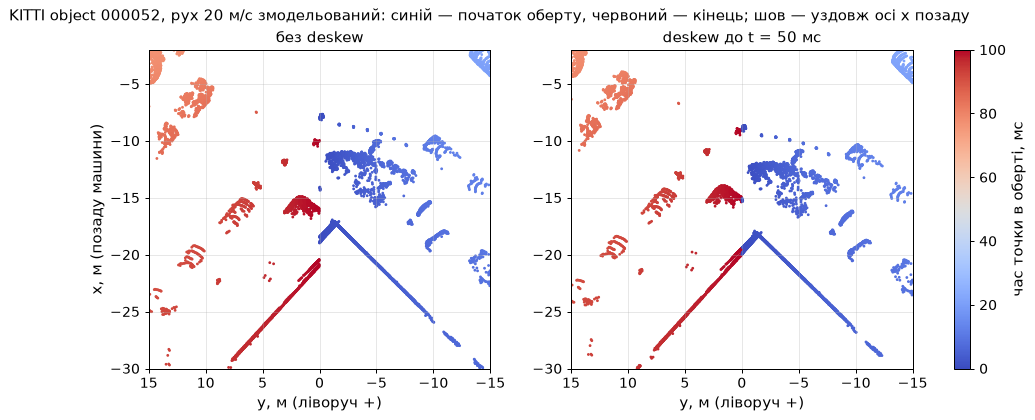

In [2]:
P.seam_plot(v=20.0)

## Інтерактивно
Перемикайте deskew і рухайте Δt: deskew прибирає перекіс оберту, але **не** помилку мітки часу камери.

Під картинкою — на скільки пікселів deskew зсуває точки. У центрі кадру майже нічого не змінюється: камеру тригерить
LiDAR, коли дивиться вперед (як у KITTI), тож точки по центру зняті саме в момент кадру. На краях FOV 81° (камера KITTI) — ±11 мс
оберту, і там різниця вже помітна: дивіться на стовпи біля лівого й правого країв (слайд «Час · deskew», 32).

In [3]:
P.time_panel();

interactive(children=(FloatSlider(value=15.0, continuous_update=False, description='швидкість, м/с', layout=La…

Попередньо запущений кадр для показу без ядра: 15 м/с, 90°/с і 20 мс розсинхрону з deskew — зсув ≈ 23 px лишається,
бо це вже помилка мітки часу камери, а не перекіс оберту.

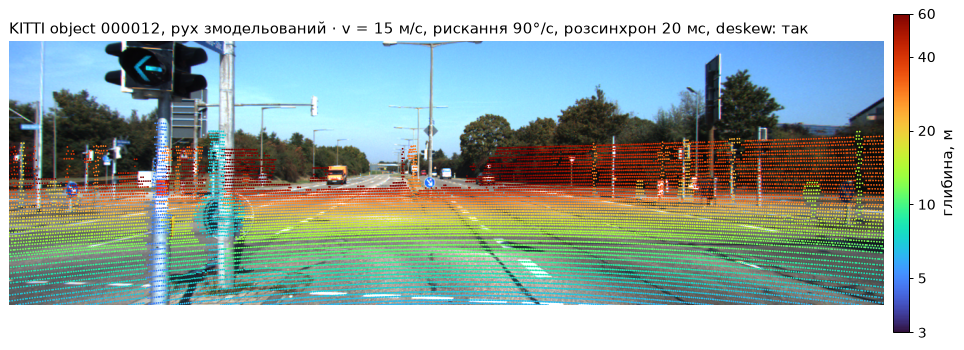

прогноз зсуву від обертання f·ω·Δt = 22.7 px — однаковий на будь-якій дальності; поступальна частина v·Δt дає зсув, що спадає з дальністю
deskew зсуває точки в кадрі: медіана 6.4 px, на краях кадру 18.8 px (в центрі майже 0: камеру тригерить LiDAR, коли дивиться вперед, як у KITTI)


In [4]:
P.time_panel(static=dict(v=15, yaw_rate=90, dt_ms=20, deskew=True))

## Ваш deskew
Пози сенсора відомі на сітці 200 Гц (як з IMU). Інтерполюйте обертання через Slerp, позицію — лінійно, і переведіть кожну
точку в рамку моменту `t_ref`. Скан — той самий кадр KITTI зі змодельованим рухом (або синтетика без даних).

In [5]:
from scipy.spatial.transform import Rotation, Slerp

def deskew(xyz, t, ts, Rs, ps, t_ref):
    sl = Slerp(ts, Rotation.from_matrix(Rs))
    Ri = sl(np.clip(t, ts[0], ts[-1])).as_matrix()
    pi = np.stack([np.interp(t, ts, ps[:, k]) for k in range(3)], 1)
    Xw = np.einsum('nij,nj->ni', Ri, xyz) + pi
    Rr = sl([t_ref]).as_matrix()[0]
    pr = np.array([np.interp(t_ref, ts, ps[:, k]) for k in range(3)])
    return (Xw - pr) @ Rr


In [6]:
v, w = 15.0, 90.0
scan = P.demo2_scan(v, w)              # KITTI 000012 зі змодельованим рухом або синтетична сцена
ts = np.linspace(0, 0.1, 21)
Rs, ps = G.pose(ts, v, w)              # пози сенсора на сітці 200 Гц: 21×3×3 і 21×3
mine = deskew(scan['xyz'], scan['t'], ts, Rs, ps, 0.05)
ideal = G.to_frame_at(scan, 0.05, v, w)
err = np.linalg.norm(mine - ideal, axis=1)
print(f'{len(err)} точок; відхилення від ідеального deskew: медіана {np.median(err) * 100:.2f} см, max {err.max() * 100:.2f} см')
assert np.median(err) < 0.01

120007 точок; відхилення від ідеального deskew: медіана 0.00 см, max 0.00 см


## Питання

1. При ω = 90°/с і Δt = 10 мс зсув ≈ 16 px (f = 1000). Порівняйте з помилкою калібрування 0.5° при тому ж f (≈ 8.7 px;
   у KITTI, f = 721.5, — 11.3 проти 6.3 px). Що виправляти першим?
2. Чому deskew з ідеальними позами не рятує, якщо мітка часу камери хибна?
3. Як зміниться картина для flash-LiDAR?
4. Чи можна змоделювати вдвічі швидший рух, проріджуючи записані скани (кожен другий оберт за «вдвічі менший час»)?
   Підказка: перекіс у метрах — це `v·T` оберту; кожен збережений скан записаний на справжній швидкості.